In [16]:
"""
Imports for the entire project
"""

import math
import random
from collections import deque
from typing import List, Dict, Tuple, Optional, Union
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

import time
import matplotlib.pyplot as plt

### 1. Board Representation & Graph Precomputation
This section defines the static move graph for a 5x5 Gardner Chess board. By identifying all possible geometric moves (sliding paths, knight leaps, and pawn promotions) once at startup, we avoid expensive pathfinding calculations during MCTS and neural network training.

In [ ]:
"""
Builds the move graph

Vertices are squares on the board
Edges are ways to move from source to destination square
"""
device: torch.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Piece IDs: 0=empty, 1..6=White (P,N,B,R,Q,K), -1..-6=Black (p,n,b,r,q,k)
EMPTY: int = 0
P, N, B, R, Q, K = 1, 2, 3, 4, 5, 6

def build_5x5_move_graph() -> Tuple[List[Tuple[int, int, int]], Dict[Tuple[int, int, int], int], torch.Tensor, torch.Tensor]:
    """Precompute all geometrically valid directed edges (src, dst, promo) on a 5x5 board."""
    edges: List[Tuple[int, int, int]] = [] # list of (src_sq, dst_sq, promo_type) where promo_type in {0, N, B, R, Q}
    edge_to_idx: Dict[Tuple[int, int, int], int] = {}

    def add_edge(src_row: int,
                 src_col: int,
                 dst_row: int,
                 dst_col: int,
                 promo: int = 0
        ) -> None:
        src = src_row * 5 + src_col
        dst = dst_row * 5 + dst_col
        key = (src, dst, promo)
        if key not in edge_to_idx:
            edge_to_idx[key] = len(edges)
            edges.append(key)

    for row in range(5):
        for col in range(5):

            # Queen-like sliding directions (8 directions, 1..4 steps)
            for delta_row, delta_col in [(-1,0),(1,0),(0,-1),(0,1),(-1,-1),(-1,1),(1,-1),(1,1)]:
                for step in range(1, 5):
                    next_row, next_col = row + delta_row*step, col + delta_col*step
                    if 0 <= next_row < 5 and 0 <= next_col < 5:
                        add_edge(row, col, next_row, next_col, 0)

            # Knight jumps
            for delta_row, delta_col in [(-2,-1),(-2,1),(-1,-2),(-1,2),(1,-2),(1,2),(2,-1),(2,1)]:
                next_row, next_col = row + delta_row, col + delta_col
                if 0 <= next_row < 5 and 0 <= next_col < 5:
                    add_edge(row, col, next_row, next_col, 0)

            # Pawn promotions (from rank 3->4 for white, or 1->0 for black; board is oriented to current player)
            if row == 3:
                for delta_col in [-1, 0, 1]:
                    next_col = col + delta_col
                    if 0 <= next_col < 5:
                        for promo in [N, B, R, Q]:
                            add_edge(row, col, 4, next_col, promo)

    src_idx = torch.tensor([edge[0] for edge in edges], dtype=torch.long)
    dst_idx = torch.tensor([edge[1] for edge in edges], dtype=torch.long)
    return edges, edge_to_idx, src_idx, dst_idx

EDGES, EDGE_TO_IDX, SRC_IDX, DST_IDX = build_5x5_move_graph()
NUM_NODES: int = 25 # There are 25 individual grid squares
NUM_EDGES: int = len(EDGES)
print(f"5x5 Move Graph: {NUM_NODES} nodes, {NUM_EDGES} directed edges")

Using device: cuda
5x5 Move Graph: 25 nodes, 468 directed edges


### 2. Gardner Chess Environment
Here, we implement the core mechanics of 5x5 Gardner Mini-Chess. Pawns can only advance one step, and castling/en-passant are disabled. The board state is vertically flipped and inverted when it is the opponent's turn so that the current player always attacks upwards from their own perspective.

In [ ]:
"""
Builds the 5x5 Gardner Mini-Chess (board always oriented to current player = +1) game.

Due to the smaller board size, pawns do not have an initial two-square advance.
En passant and castling are not implemented.
"""

class GardnerChess:
    """Lightweight 5x5 Gardner Mini-Chess (board always oriented to current player = +1)."""
    board: np.ndarray
    turn: int
    move_count: int

    def __init__(self) -> None:
        self.reset()

    def reset(self) -> "GardnerChess":
        """Resets the GardnerChess object to the original state"""
        # Row 0 = White back rank, Row 4 = Black back rank
        # Board looks upside down but top row is row 0 and bottom row is row 4
        self.board = np.array([
            [ R,  N,  B,  Q,  K],
            [ P,  P,  P,  P,  P],
            [ 0,  0,  0,  0,  0],
            [-P, -P, -P, -P, -P],
            [-R, -N, -B, -Q, -K],
        ], dtype=np.int8)
        self.turn = 1       # 1 = White, -1 = Black
        self.move_count = 0
        return self

    def clone(self) -> "GardnerChess":
        """Clones the 'GardnerChess' object and returns a new one"""
        game_clone = GardnerChess.__new__(GardnerChess)
        game_clone.board = self.board.copy()
        game_clone.turn = self.turn
        game_clone.move_count = self.move_count
        return game_clone

    def canonical_board(self) -> np.ndarray:
        """Flip board vertically and negate pieces so current player always moves 'up' (row 0 -> 4)."""
        if self.turn == 1:
            return self.board.copy()
        return -np.flip(self.board, axis=0).copy()

    def _pseudo_legal_moves(self, canonical_b: np.ndarray) -> List[Tuple[int, int, int]]:
        """
        Generate pseudo-legal moves on a canonical board (current player > 0, moving up).
        Returns a list of (src, dst, promo) tuples.

        promo = 0 means no promotion.
        promo = 1..6 means promotion to that piece.

        Pseudo legal means it considers the move without checking for check or checkmate on own king.

        Enemy pieces are encoded as negative. Empty slots are encoded as 0.
        Pieces only move to slots with values <= 0
        """

        moves: List[Tuple[int, int, int]] = []
        for row in range(5):
            for col in range(5):
                piece = canonical_b[row, col]
                if piece <= 0:
                    continue

                # Pawn
                if piece == P:
                    # Moving the pawn forward
                    if row + 1 < 5 and canonical_b[row+1, col] == 0:
                        if row + 1 == 4:
                            for promo in [Q, R, B, N]:
                                moves.append((row*5+col, (row+1)*5+col, promo))
                        else:
                            moves.append((row*5+col, (row+1)*5+col, 0))

                    # Checking for diagonal captures
                    for delta_col in [-1, 1]:
                        next_col = col + delta_col

                        if row + 1 < 5 and 0 <= next_col < 5 and canonical_b[row+1, next_col] < 0:
                            if row + 1 == 4:
                                for promo in [Q, R, B, N]:
                                    moves.append((row*5+col, (row+1)*5+next_col, promo))
                            else:
                                moves.append((row*5+col, (row+1)*5+next_col, 0))
                # Knight
                elif piece == N:
                    for delta_row, delta_col in [(-2,-1),(-2,1),(-1,-2),(-1,2),(1,-2),(1,2),(2,-1),(2,1)]:
                        next_row, next_col = row+delta_row, col+delta_col

                        if 0 <= next_row < 5 and 0 <= next_col < 5 and canonical_b[next_row, next_col] <= 0:
                            moves.append((row*5+col, next_row*5+next_col, 0))
                # King
                elif piece == K:
                    for delta_row in [-1,0,1]:
                        for delta_col in [-1,0,1]:

                            if delta_row == 0 and delta_col == 0:
                                continue

                            next_row, next_col = row+delta_row, col+delta_col

                            if 0 <= next_row < 5 and 0 <= next_col < 5 and canonical_b[next_row, next_col] <= 0:
                                moves.append((row*5+col, next_row*5+next_col, 0))
                # Rook, Bishop, or Queen
                else:
                    # Add more directions depending on the piece
                    directions: List[Tuple[int, int]] = []

                    if piece in (R, Q):
                        directions += [(-1,0),(1,0),(0,-1),(0,1)]

                    if piece in (B, Q):
                        directions += [(-1,-1),(-1,1),(1,-1),(1,1)]

                    for delta_row, delta_col in directions:
                        for step in range(1, 5):

                            next_row, next_col = row+delta_row*step, col+delta_col*step

                            # Check if it's within the bounds of the board
                            if not (0 <= next_row < 5 and 0 <= next_col < 5):
                                break

                            if canonical_b[next_row, next_col] == 0:
                                moves.append((row*5+col, next_row*5+next_col, 0))
                            elif canonical_b[next_row, next_col] < 0:
                                moves.append((row*5+col, next_row*5+next_col, 0))
                                break
                            else:
                                break
        return moves

    def _is_king_attacked(self, canonical_b: np.ndarray) -> bool:
        """Check if current player's king (+K) is attacked on canonical board."""
        opp_canonical_b = -np.flip(canonical_b, axis=0)

        for src, dst, _ in self._pseudo_legal_moves(opp_canonical_b):
            # See where the move lands on the flipped board
            dst_row, dst_col = divmod(dst, 5)
            # Flip back to canonical_b's coordinates
            if canonical_b[4 - dst_row, dst_col] == K:
                return True
        return False

    def legal_action_indices(self) -> List[int]:
        """Filters all the pseudo legal moves that leave the king in check"""
        canonical_b = self.canonical_board()
        legal_actions: List[int] = []

        for src, dst, promo in self._pseudo_legal_moves(canonical_b):
            next_b = canonical_b.copy()
            src_row, src_col = divmod(src, 5)
            dst_row, dst_col = divmod(dst, 5)

            # Modify the board after the current move
            if promo != 0:
                next_b[dst_row, dst_col] = promo
            else:
                next_b[dst_row, dst_col] = next_b[src_row, src_col]

            next_b[src_row, src_col] = 0

            # Check if the king is attacked after playing the move
            if not self._is_king_attacked(next_b):
                legal_actions.append(EDGE_TO_IDX[(src, dst, promo)])

        return legal_actions

    def step(self, action_idx: int) -> None:
        src, dst, promo = EDGES[action_idx]
        canonical_b = self.canonical_board()

        src_row, src_col = divmod(src, 5)
        dst_row, dst_col = divmod(dst, 5)

        if promo != 0:
            canonical_b[dst_row, dst_col] = promo
        else:
            canonical_b[dst_row, dst_col] = canonical_b[src_row, src_col]

        canonical_b[src_row, src_col] = 0

        # Write back to absolute board
        if self.turn == 1:
            self.board = canonical_b
        else:
            self.board = -np.flip(canonical_b, axis=0)

        self.turn *= -1
        self.move_count += 1

    def game_result(self, max_moves: int = 80) -> Optional[float]:
        """Returns None if ongoing, or outcome from CURRENT player's perspective (-1, 0, +1)."""
        if self.move_count >= max_moves:
            return 0.0

        legal_actions = self.legal_action_indices()

        if len(legal_actions) == 0:
            if self._is_king_attacked(self.canonical_board()):
                return -1.0  # Current player is checkmated
            return 0.0       # Stalemate
        return None

### 3. Feature Encoding
This module converts the symbolic board layout into numerical tensors. Node features contain piece type, turn indicator, and normalized turn metrics. Edge features map the static geometry of possible moves combined with a dynamic legality flag.

In [ ]:
"""
Encodes each 5x5 Gardner Mini-Chess position into Node and Edge feature tensors
for both Mini-AlphaZero (CNN) and Mini-AlphaGateau (GNN).

Since the geometry of every possible move (direction, distance, promotion type)
never changes during a game, precompute those static edge features once at
startup and only update the legality flag on each turn.

The Node features per square is simplified compared to the original AlphaZero/AlphaGateau paper.
There are no previous positions, repetition, castling, or no-progress planes.
"""

# Node features per square:
#   0-5  : Current player's pieces (P, N, B, R, Q, K) one-hot
#   6-11 : Opponent's pieces (p, n, b, r, q, k) one-hot
#   12    : Current player's color (1.0 = White, 0.0 = Black)
#   13    : Normalized move count (move_count / 80.0, capped at 1.0)
NODE_FEAT_DIM = 14

# Edge features per move:
#   0     : Dynamic legality flag (1.0 if legal in current position, else 0.0)
#   1-2  : Normalized (delta_row, delta_col) displacement in [-1.0, 1.0]
#   3-6  : Pawn promotion one-hot (Knight, Bishop, Rook, Queen)
EDGE_FEAT_DIM = 7

# Precompute the static edge feature matrix once for all possible moves
BASE_EDGE_FEATS = np.zeros((NUM_EDGES, EDGE_FEAT_DIM), dtype=np.float32)

for idx, (src_square, dst_square, promo) in enumerate(EDGES):
    # Convert flat square indices (0..24) into (row, col) coordinates (0..4)
    src_row, src_col = divmod(src_square, 5)
    dst_row, dst_col = divmod(dst_square, 5)

    # Store move displacement normalized by max board span (4 squares)
    # Column 0 is left as 0.0 here and filled dynamically with move legality later
    BASE_EDGE_FEATS[idx, 1] = (dst_row - src_row) / 4.0
    BASE_EDGE_FEATS[idx, 2] = (dst_col - src_col) / 4.0

    # One-hot encode pawn promotion target (all 0.0 for non-promotion moves)
    if promo == N:
        BASE_EDGE_FEATS[idx, 3] = 1.0
    elif promo == B:
        BASE_EDGE_FEATS[idx, 4] = 1.0
    elif promo == R:
        BASE_EDGE_FEATS[idx, 5] = 1.0
    elif promo == Q:
        BASE_EDGE_FEATS[idx, 6] = 1.0


def encode_state(game: GardnerChess)-> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    Converts the current game state into model-ready tensors.

    Returns:
      node_feats : np.ndarray of shape (25, 14) - per-square features (used as nodes by GNN, reshaped to 5x5x14 by CNN)
      edge_feats : np.ndarray of shape (NUM_EDGES, 7) - static move geometry + current move legality
      legal_mask : np.ndarray of shape (NUM_EDGES,) - binary mask (1.0 = legal move, 0.0 = illegal)
    """

    # Orient board to the current player's perspective
    b = game.canonical_board()
    node_feats = np.zeros((25, NODE_FEAT_DIM), dtype=np.float32)

    # Flatten 5x5 board to 25 squares and populate the 12 piece one-hot channels
    flat_b = b.reshape(-1)
    for i, p in enumerate(flat_b):

        # Current player's piece
        if p > 0:
            node_feats[i, p - 1] = 1.0

        # Opponent's piece
        elif p < 0:
            node_feats[i, 6 + (-p) - 1] = 1.0

    # Current player's turn
    if game.turn == 1:
        node_feats[:, 12] = 1.0
    else:
        node_feats[:, 12] = 0.0

    # Normalized turn count
    node_feats[:, 13] = min(game.move_count / 80.0, 1.0)

    # Build a binary mask over all possible edges indicating which moves are legal
    legal = game.legal_action_indices()
    legal_mask = np.zeros(NUM_EDGES, dtype=np.float32)
    legal_mask[legal] = 1.0

    # Copy precomputed static edge features and inject the legality flag into column 0
    edge_feats = BASE_EDGE_FEATS.copy()
    edge_feats[:, 0] = legal_mask
    return node_feats, edge_feats, legal_mask

### 4. Neural Network Architectures
We define both competitor architectures here:
- **Mini-AlphaZero (CNN)**: Converts node feature sequences back into a 5x5 grid and processes them using 2D convolutional layers and residual connections.
- **Mini-AlphaGateau (GNN)**: Formulates the board as a graph and uses self-attention message passing over nodes and precomputed edges.

In [ ]:
"""
Baseline Model: Mini-AlphaZero

Takes the node_features, runs 4 standard AlphaZero residual blocks
Ouputs the policy logits and a scalar value in [-1. 1]

NODE_FEAT_DIM is reduced from 119 to 14 compared to original AlphaZero and AlphaGateau papers
Hidden units are reduced to 64 from 128 from the AlphaGateau paper.

These were done for computational reasons.
"""

# Original AlphaZero uses CNNs with a 3x3 kernel
class ResBlockCNN(nn.Module):
    def __init__(self, channels: int) -> None:
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, kernel_size=3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(channels)
        self.conv2 = nn.Conv2d(channels, channels, kernel_size=3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(channels)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(x + out)


class MiniAlphaZero(nn.Module):
    def __init__(self, hidden_dim=64, num_blocks=4) -> None:
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(NODE_FEAT_DIM, hidden_dim, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(hidden_dim),
            nn.ReLU(),
        )

        self.blocks = nn.ModuleList([ResBlockCNN(hidden_dim) for _ in range(num_blocks)])

        # Policy head
        self.policy_conv = nn.Sequential(
            nn.Conv2d(hidden_dim, 32, kernel_size=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(),
        )
        self.policy_fc = nn.Linear(32 * 25, NUM_EDGES)

        # Value head
        self.value_conv = nn.Sequential(
            nn.Conv2d(hidden_dim, 8, kernel_size=1, bias=False),
            nn.BatchNorm2d(8),
            nn.ReLU(),
        )
        self.value_fc = nn.Sequential(
            nn.Linear(8 * 25, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1),
            nn.Tanh(),
        )

    def forward(self,
                node_feats: torch.Tensor,
                edge_feats: Optional[torch.Tensor] = None
                ) -> Tuple[torch.Tensor, torch.Tensor]:
        # node_feats: (B, 25, 14) -> (B, 14, 5, 5)
        x = node_feats.transpose(1, 2).reshape(-1, NODE_FEAT_DIM, 5, 5)
        x = self.stem(x)
        for blk in self.blocks:
            x = blk(x)

        p = self.policy_conv(x).flatten(1)
        policy_logits = self.policy_fc(p)

        v = self.value_conv(x).flatten(1)
        value = self.value_fc(v).squeeze(-1)
        return policy_logits, value

In [ ]:
"""
Modified Model: Mini-AlphaGateau

Takes node and edge features, runs 4 standard AlphaGateau GNN blocks,
and outputs policy logits and a scalar evaluation in [-1, 1].
"""

class GATEAULayer(nn.Module):
    def __init__(self, hidden_dim: int):
        super().__init__()

        self.W_u = nn.Linear(hidden_dim, hidden_dim, bias=False)
        self.W_v = nn.Linear(hidden_dim, hidden_dim, bias=False)
        self.W_e = nn.Linear(hidden_dim, hidden_dim, bias=False)

        self.attn_a = nn.Linear(hidden_dim, 1, bias=False)

        self.W_0 = nn.Linear(hidden_dim, hidden_dim, bias=False)
        self.W_h = nn.Linear(hidden_dim, hidden_dim, bias=False)
        self.W_g = nn.Linear(hidden_dim, hidden_dim, bias=False)

    def forward(self, h: torch.Tensor, g: torch.Tensor, src_idx: torch.Tensor, dst_idx: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        # h: (B, N, K), g: (B, E, K)
        B, N, K = h.shape
        E = g.shape[1]

        # Eq. 4: Update edge features based on source and destination node features
        h_u = self.W_u(h)[:, src_idx, :]
        h_v = self.W_v(h)[:, dst_idx, :]
        g_new = h_u + self.W_e(g) + h_v

        # Eq. 5: Grouped attention weights over source node indices
        scores = F.leaky_relu(self.attn_a(g_new).squeeze(-1), negative_slope=0.2)

        max_per_node = torch.full((B, N), -1e9, device=h.device, dtype=h.dtype)
        max_per_node.scatter_reduce_(1, src_idx.unsqueeze(0).expand(B, E), scores, reduce="amax", include_self=True)

        exp_scores = torch.exp(scores - max_per_node[:, src_idx])
        sum_exp = torch.zeros((B, N), device=h.device, dtype=h.dtype)
        sum_exp.scatter_add_(1, src_idx.unsqueeze(0).expand(B, E), exp_scores)

        alpha = exp_scores / (sum_exp[:, src_idx] + 1e-8)

        # Eq. 6: Aggregate weighted messages to update node representations
        msg = self.W_h(h)[:, dst_idx, :] + self.W_g(g)
        weighted_msg = alpha.unsqueeze(-1) * msg
        agg = torch.zeros((B, N, K), device=h.device, dtype=h.dtype)
        agg.scatter_add_(1, src_idx.view(1, E, 1).expand(B, E, K), weighted_msg)

        h_new = self.W_0(h) + agg
        return h_new, g_new


class BNR(nn.Module):
    """BatchNorm + ReLU sequential block over the feature dimension."""
    def __init__(self, hidden_dim: int):
        super().__init__()
        self.bn = nn.BatchNorm1d(hidden_dim)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Reshape for BatchNorm1d: (B, L, K) -> (B, K, L)
        return F.relu(self.bn(x.transpose(1, 2)).transpose(1, 2))


class ResGATEAUBlock(nn.Module):
    """Residual block wrapping two layers of GATEAU with BatchNorm and ReLU."""
    def __init__(self, hidden_dim: int):
        super().__init__()
        self.bnr_h1 = BNR(hidden_dim)
        self.bnr_g1 = BNR(hidden_dim)

        self.gat1 = GATEAULayer(hidden_dim)

        self.bnr_h2 = BNR(hidden_dim)
        self.bnr_g2 = BNR(hidden_dim)

        self.gat2 = GATEAULayer(hidden_dim)

    def forward(self, h: torch.Tensor, g: torch.Tensor, src_idx: torch.Tensor, dst_idx: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        dh, dg = self.gat1(self.bnr_h1(h), self.bnr_g1(g), src_idx, dst_idx)
        dh, dg = self.gat2(self.bnr_h2(dh), self.bnr_g2(dg), src_idx, dst_idx)

        return h + dh, g + dg


class MiniAlphaGateau(nn.Module):
    """Mini-AlphaGateau model architecture optimized for 5x5 Gardner Chess."""
    def __init__(self, hidden_dim: int = 64, num_blocks: int = 4):
        super().__init__()
        self.register_buffer("src_idx", SRC_IDX)
        self.register_buffer("dst_idx", DST_IDX)

        self.node_in = nn.Linear(NODE_FEAT_DIM, hidden_dim)
        self.edge_in = nn.Linear(EDGE_FEAT_DIM, hidden_dim)

        self.blocks = nn.ModuleList([ResGATEAUBlock(hidden_dim) for _ in range(num_blocks)])

        # Value head with attention pooling over nodes
        self.val_bnr1 = BNR(hidden_dim)
        self.val_lin1 = nn.Linear(hidden_dim, hidden_dim)
        self.val_bnr2 = BNR(hidden_dim)
        self.att_pool = nn.Linear(hidden_dim, 1, bias=False)
        self.val_out = nn.Linear(hidden_dim, 1)

        # Policy head mapping edge representations directly to actions
        self.pol_bnr1 = BNR(hidden_dim)
        self.pol_lin1 = nn.Linear(hidden_dim, hidden_dim)
        self.pol_bnr2 = BNR(hidden_dim)
        self.pol_out = nn.Linear(hidden_dim, 1)

    def forward(self, node_feats: torch.Tensor, edge_feats: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        h = self.node_in(node_feats)
        g = self.edge_in(edge_feats)

        for block in self.blocks:
            h, g = block(h, g, self.src_idx, self.dst_idx)

        # Compute Value
        vh = self.val_bnr2(self.val_lin1(self.val_bnr1(h)))
        w = F.softmax(F.leaky_relu(self.att_pool(vh).squeeze(-1), 0.2), dim=-1)
        pooled = torch.sum(w.unsqueeze(-1) * vh, dim=1)
        value = torch.tanh(self.val_out(F.relu(pooled))).squeeze(-1)

        # Compute Policy
        pg = self.pol_bnr2(self.pol_lin1(self.pol_bnr1(g)))
        policy_logits = self.pol_out(pg).squeeze(-1)

        return policy_logits, value

### 5. Monte Carlo Tree Search (MCTS)
This module implements PUCT-driven MCTS. It governs state selection, expansion, neural network evaluation, and backward propagation. It also supports Dirichlet noise for exploration during self-play and provides visit-count distributions to train the policy network.

In [ ]:
"""
Lightweight Monte Carlo Tree Search (MCTS) and Self-Play Generator.
Shared by both Mini-AlphaZero and Mini-AlphaGateau
"""

class MCTSNode:
    """Represents a single board state in the MCTS search tree."""
    prior_prob: float
    visit_count: int
    total_value: float
    children: Dict[int, "MCTSNode"]

    def __init__(self, prior_prob: float = 0.0) -> None:
        self.prior_prob = prior_prob  # P(s, a): prior move probability from the neural network
        self.visit_count = 0          # N(s, a): number of times this node was visited during search
        self.total_value = 0.0        # W(s, a): cumulative backed-up value from all simulations through this node
        self.children = {}            # Maps action_idx -> child MCTSNode

    @property
    def mean_value(self) -> float:
        """Q(s, a): average expected outcome from this node's player's perspective."""
        if self.visit_count > 0:
            return self.total_value / self.visit_count
        else:
            return 0.0

@torch.no_grad()
def predict_single(model: nn.Module, game: GardnerChess) -> Tuple[np.ndarray, float]:
    """
    Runs a single forward pass of the neural network on the current board state.
    Returns:
      action_probs : np.ndarray of shape (NUM_EDGES,) - valid probability distribution over legal moves
      state_value  : float in [-1, 1] - predicted outcome from the current player's perspective
    """
    node_feats, edge_feats, legal_mask = encode_state(game)

    # Create batch dimension of 1 and move tensors
    node_tensor = torch.from_numpy(node_feats).unsqueeze(0).to(device)
    edge_tensor = torch.from_numpy(edge_feats).unsqueeze(0).to(device)

    policy_logits, value_pred = model(node_tensor, edge_tensor)
    policy_logits = policy_logits.squeeze(0).cpu().numpy()

    # Mask out illegal moves before applying softmax
    policy_logits[legal_mask == 0] = -1e9
    action_probs = np.exp(policy_logits - np.max(policy_logits))  # Subtract max for numerical stability
    action_probs *= legal_mask
    action_probs /= (action_probs.sum() + 1e-8)

    return action_probs, float(value_pred.item())


def run_mcts(model: nn.Module,
             game: GardnerChess,
             num_simulations: int = 32,
             c_puct: float = 1.5,
             add_dirichlet_noise: bool = True
             ) -> np.ndarray:
    """
    Runs PUCT MCTS from the given game state.
    Returns:
      mcts_policy : np.ndarray of shape (NUM_EDGES,) - normalized visit-count distribution at the root
    """
    root_node = MCTSNode()
    prior_probs, _ = predict_single(model, game)
    legal_actions = game.legal_action_indices()

    # Add Dirichlet noise at the root during self-play to encourage exploring diverse openings
    if add_dirichlet_noise and len(legal_actions) > 0:
        dirichlet_noise = np.random.dirichlet([0.3] * len(legal_actions))
        for i, action_idx in enumerate(legal_actions):
            prior_probs[action_idx] = 0.75 * prior_probs[action_idx] + 0.25 * dirichlet_noise[i]

    # Expand root node with all legal moves
    for action_idx in legal_actions:
        root_node.children[action_idx] = MCTSNode(prior_prob=prior_probs[action_idx])

    for _ in range(num_simulations):
        current_node = root_node
        sim_game = game.clone()
        search_path = [current_node]

        # 1. SELECTION: Traverse down the tree using the PUCT formula until reaching a leaf node
        while current_node.children:
            sqrt_parent_visits = math.sqrt(current_node.visit_count + 1e-8)
            best_action, best_puct_score = None, -1e9

            for action_idx, child_node in current_node.children.items():
                # Negate child_node.mean_value because the child state is from the opponent's perspective
                exploitation = -child_node.mean_value
                exploration = c_puct * child_node.prior_prob * sqrt_parent_visits / (1 + child_node.visit_count)
                puct_score = exploitation + exploration

                if puct_score > best_puct_score:
                    best_puct_score = puct_score
                    best_action = action_idx

            sim_game.step(best_action)
            current_node = current_node.children[best_action]
            search_path.append(current_node)

        # 2. EVALUATION & EXPANSION: Score the leaf state (terminal result or neural network value)
        game_outcome = sim_game.game_result()

        # Use neural network's prediction of the game
        if game_outcome is None:
            leaf_probs, leaf_value = predict_single(model, sim_game)

            for action_idx in sim_game.legal_action_indices():
                current_node.children[action_idx] = MCTSNode(prior_prob=leaf_probs[action_idx])

        # Use the game's outcome
        else:
            leaf_value = game_outcome

        # 3. BACKUP: Propagate the leaf value back up the path, flipping sign at each ply
        backed_up_value = leaf_value

        for visited_node in reversed(search_path):
            visited_node.visit_count += 1
            visited_node.total_value += backed_up_value
            backed_up_value = -backed_up_value

    # Build the improved MCTS policy target from root visit counts
    mcts_policy = np.zeros(NUM_EDGES, dtype=np.float32)

    for action_idx, child_node in root_node.children.items():
        mcts_policy[action_idx] = child_node.visit_count

    mcts_policy /= (mcts_policy.sum() + 1e-8)

    return mcts_policy


def play_selfplay_game(model: nn.Module, num_simulations: int = 32, temperature_moves: int = 10) -> List[Tuple[np.ndarray, np.ndarray, np.ndarray, np.float32]]:
    """
    Plays one full game of 5x5 Gardner Mini-Chess via self-play MCTS.
    Returns:
      training_samples : list of (node_feats, edge_feats, mcts_policy, target_value) tuples
    """
    game = GardnerChess()
    game_history: List[Tuple[np.ndarray, np.ndarray, np.ndarray]] = []  # Stores (node_feats, edge_feats, mcts_policy) at each turn

    while True:
        game_outcome = game.game_result()
        if game_outcome is not None:
            # Assign final game outcome (+1 win, 0 draw, -1 loss) to every recorded state,
            # flipping the sign each since players alternate turns
            training_samples: List[Tuple[np.ndarray, np.ndarray, np.ndarray, np.float32]] = []
            target_value = game_outcome

            for node_feats, edge_feats, mcts_policy in reversed(game_history):
                target_value = -target_value
                training_samples.append((node_feats, edge_feats, mcts_policy, np.float32(target_value)))
            return training_samples

        node_feats, edge_feats, _ = encode_state(game)
        mcts_policy = run_mcts(model, game, num_simulations=num_simulations, add_dirichlet_noise=True)
        game_history.append((node_feats, edge_feats, mcts_policy))

        # Sample proportionally to visit counts early in the game for diversity, then play greedily
        if game.move_count < temperature_moves:
            chosen_action = np.random.choice(NUM_EDGES, p=mcts_policy)
        else:
            chosen_action = int(np.argmax(mcts_policy))

        game.step(chosen_action)

In [ ]:
"""
Compare the parameters of the Mini-AlphaZero and Mini-AlphaGateau models

Although Mini-AlphaGateau uses a larger hidden dimension than Mini-AlphaZero,
they have similar parameter counts. This is because the core layers in Mini-AlphaGateau
use about 2/3 as many weights for the same width and there is no dense policy head.
"""

def count_params(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# Check parameter counts and match them before training
az_model = MiniAlphaZero(hidden_dim=64, num_blocks=4).to(device)
ag_model = MiniAlphaGateau(hidden_dim=117, num_blocks=4).to(device)

print(f"MiniAlphaZero params:   {count_params(az_model):,}")
print(f"MiniAlphaGateau params: {count_params(ag_model):,}")

MiniAlphaZero params:   694,565
MiniAlphaGateau params: 693,344


### 6. Training Pipeline
Here is the primary reinforcement learning training loop. Models generate training targets dynamically through self-play, update weights using an Adam optimizer on a rolling replay buffer, and serialize their weights periodically.

In [ ]:
"""
Training the Mini-AlphaZero and Mini-AlphaGateau models using the same parameters
"""

def train_model(
      model: nn.Module,
      name: str,
      num_iters: int = 10,
      games_per_iter: int = 10,
      num_simulations: int = 32,
      batch_size: int = 64,
      window_size: int = 5000,
      lr: float = 1e-3,
      seed: int = 42,
      checkpoint_freq: int = 5
      ) -> Dict[str, List[float]]:
    """Self-play RL training loop with timing, loss logging, and periodic checkpoint saving."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    replay_buffer = deque(maxlen=window_size)
    metrics = {"total_loss": [], "policy_loss": [], "value_loss": [], "elapsed_sec": []}
    start_time = time.time()

    print(f"\n=== Training {name} ({count_params(model):,} params) ===")
    for it in range(1, num_iters + 1):
      # Self-play data generation
      model.eval()
      for _ in range(games_per_iter):
        replay_buffer.extend(play_selfplay_game(model, num_simulations=num_simulations))

      # Neural network update (1 epoch over replay buffer)
      model.train()
      data = list(replay_buffer)
      random.shuffle(data)

      tot_l, pol_l, val_l, steps = 0.0, 0.0, 0.0, 0
      for i in range(0, len(data), batch_size):
          batch = data[i:i + batch_size]
          if len(batch) < 2:
              continue

          nf = torch.tensor(np.array([x[0] for x in batch]), device=device)
          ef = torch.tensor(np.array([x[1] for x in batch]), device=device)
          pi = torch.tensor(np.array([x[2] for x in batch]), device=device)
          z  = torch.tensor(np.array([x[3] for x in batch]), device=device)

          logits, v_pred = model(nf, ef)
          policy_loss = -(pi * F.log_softmax(logits, dim=-1)).sum(dim=-1).mean()
          value_loss = F.mse_loss(v_pred, z)
          loss = policy_loss + value_loss

          optimizer.zero_grad()
          loss.backward()
          optimizer.step()

          tot_l += loss.item()
          pol_l += policy_loss.item()
          val_l += value_loss.item()
          steps += 1

      elapsed = time.time() - start_time
      metrics["total_loss"].append(tot_l / max(steps, 1))
      metrics["policy_loss"].append(pol_l / max(steps, 1))
      metrics["value_loss"].append(val_l / max(steps, 1))
      metrics["elapsed_sec"].append(elapsed)

      print(
          f"Iter {it:02d}/{num_iters} | Buffer: {len(replay_buffer):4d} | "
          f"Loss: {metrics['total_loss'][-1]:.4f} "
          f"(P: {metrics['policy_loss'][-1]:.4f}, V: {metrics['value_loss'][-1]:.4f}) | "
          f"Time: {elapsed:.1f}s"
      )

      # Periodic checkpoint saving
      if it % checkpoint_freq == 0:
          checkpoint_path = f"{name.lower()}_iter{it}_seed{seed}.pt"
          torch.save(model.state_dict(), checkpoint_path)
          print(f"  -> Saved periodic checkpoint to {checkpoint_path}")

    # Save final checkpoint
    final_path = f"{name.lower()}_final_seed{seed}.pt"
    torch.save(model.state_dict(), final_path)
    print(f"  -> Saved final model to {final_path}")
    return metrics


def show_results(az_metrics: Dict, ag_metrics: Dict, title: str) -> None:
    # Plot learning curves (Loss vs Iteration AND Loss vs Wall-Clock Time)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    plt.title(title)

    axes[0].plot(az_metrics["total_loss"], marker="o", label="MiniAlphaZero (CNN)")
    axes[0].plot(ag_metrics["total_loss"], marker="s", label="MiniAlphaGateau (GNN)")
    axes[0].set_title("Total Loss vs. Iteration")
    axes[0].set_xlabel("Iteration")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(az_metrics["elapsed_sec"], az_metrics["total_loss"], marker="o", label="MiniAlphaZero (CNN)")
    axes[1].plot(ag_metrics["elapsed_sec"], ag_metrics["total_loss"], marker="s", label="MiniAlphaGateau (GNN)")
    axes[1].set_title("Total Loss vs. Wall-Clock Time (s)")
    axes[1].set_xlabel("Time (seconds)")
    axes[1].set_ylabel("Loss")
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()


=== Training MiniAlphaZero (694,565 params) ===
Iter 01/3 | Buffer:  221 | Loss: 5.8521 (P: 5.6329, V: 0.2192) | Time: 21.0s
Iter 02/3 | Buffer:  357 | Loss: 5.0357 (P: 4.6704, V: 0.3653) | Time: 31.2s
Iter 03/3 | Buffer:  551 | Loss: 4.6918 (P: 4.4118, V: 0.2799) | Time: 45.9s
  -> Saved final model to minialphazero_final_seed42.pt

=== Training MiniAlphaGateau (693,344 params) ===
Iter 01/3 | Buffer:  174 | Loss: 5.6681 (P: 5.0446, V: 0.6234) | Time: 39.3s
Iter 02/3 | Buffer:  334 | Loss: 3.0384 (P: 2.5549, V: 0.4835) | Time: 73.8s
Iter 03/3 | Buffer:  549 | Loss: 2.7254 (P: 2.2172, V: 0.5082) | Time: 123.6s
  -> Saved final model to minialphagateau_final_seed42.pt


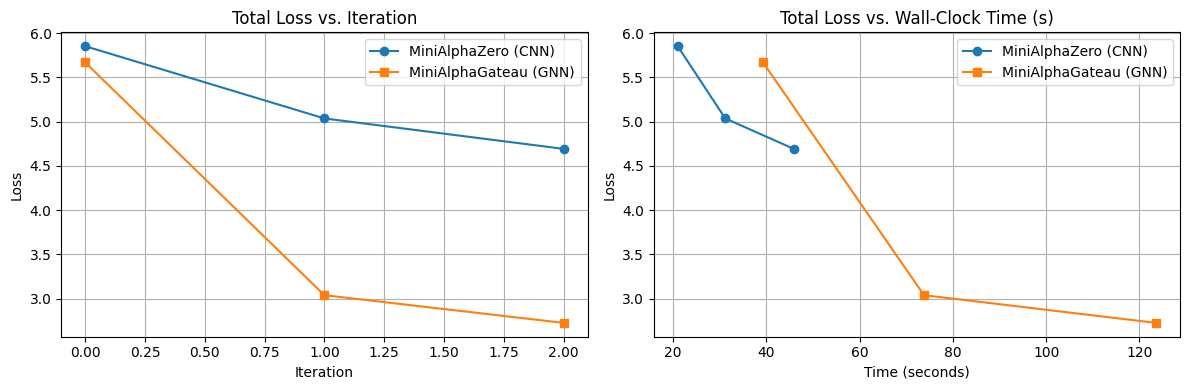

In [ ]:
# --- Quick Test to see if the code's working  ---
az_metrics = train_model(az_model, "MiniAlphaZero", num_iters=3, games_per_iter=4, num_simulations=16)
ag_metrics = train_model(ag_model, "MiniAlphaGateau", num_iters=3, games_per_iter=4, num_simulations=16)

show_results(az_metrics, ag_metrics, "Quick Test with num_iters=3, games_per_iter=4, num_simulations=16")


=== Training MiniAlphaZero (694,565 params) ===
Iter 01/25 | Buffer:  715 | Loss: 4.4922 (P: 4.1204, V: 0.3718) | Time: 111.6s
Iter 02/25 | Buffer: 1549 | Loss: 3.6404 (P: 3.4448, V: 0.1956) | Time: 255.7s
Iter 03/25 | Buffer: 2671 | Loss: 2.7893 (P: 2.6807, V: 0.1085) | Time: 425.3s
Iter 04/25 | Buffer: 3725 | Loss: 2.3614 (P: 2.2788, V: 0.0826) | Time: 581.1s
Iter 05/25 | Buffer: 4790 | Loss: 2.1872 (P: 2.1135, V: 0.0737) | Time: 752.0s
  -> Saved periodic checkpoint to minialphazero_iter5_seed42.pt
Iter 06/25 | Buffer: 5000 | Loss: 1.9700 (P: 1.9241, V: 0.0459) | Time: 942.4s
Iter 07/25 | Buffer: 5000 | Loss: 1.8723 (P: 1.8406, V: 0.0317) | Time: 1134.2s
Iter 08/25 | Buffer: 5000 | Loss: 1.8436 (P: 1.7993, V: 0.0443) | Time: 1281.9s
Iter 09/25 | Buffer: 5000 | Loss: 1.8195 (P: 1.7786, V: 0.0409) | Time: 1465.4s
Iter 10/25 | Buffer: 5000 | Loss: 1.7892 (P: 1.7517, V: 0.0375) | Time: 1627.5s
  -> Saved periodic checkpoint to minialphazero_iter10_seed42.pt
Iter 11/25 | Buffer: 5000 | 

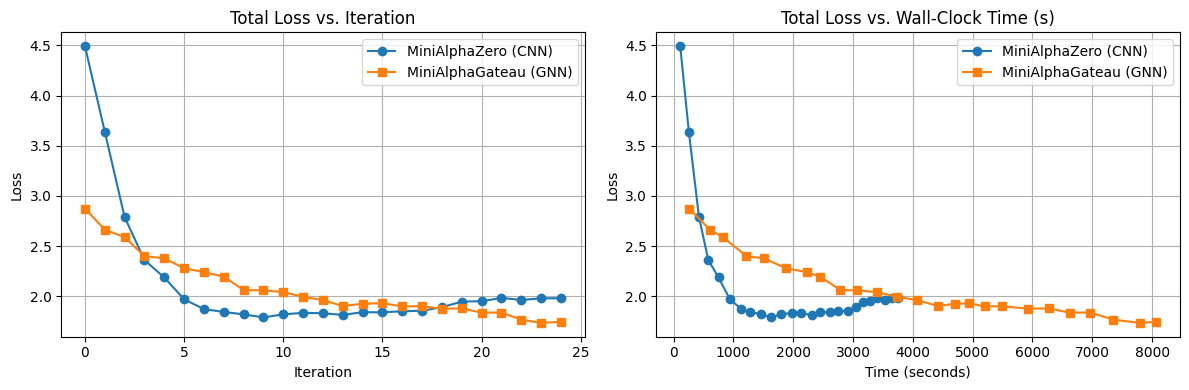

In [ ]:
# --- Main Experiment ---
az_metrics = train_model(az_model, "MiniAlphaZero", num_iters=25, games_per_iter=16, num_simulations=32)
ag_metrics = train_model(ag_model, "MiniAlphaGateau", num_iters=25, games_per_iter=16, num_simulations=32)

show_results(az_metrics, ag_metrics, "Main Experiment with num_iters=25, games_per_iter=16, num_simulations=32")

In [ ]:
def play_match(
    model_a: str,
    model_b: str,
    num_games: int = 10,
    num_simulations: int = 32,
) -> Tuple[int, int, int]:
    """
    Plays num_games between model_a and model_b, alternating colors.
    Accepts file paths to checkpoints (must be non-empty strings).
    Returns (wins_a, draws, losses_a).
    """
    # Load Model A
    if not isinstance(model_a, str) or not model_a.strip():
        raise ValueError("Model A checkpoint path must be a non-empty string!")

    if "gateau" in model_a.lower():
        m_a = MiniAlphaGateau(hidden_dim=117, num_blocks=4).to(device)
    else:
        m_a = MiniAlphaZero(hidden_dim=64, num_blocks=4).to(device)

    m_a.load_state_dict(torch.load(model_a, map_location=device))

    # Load Model B
    if not isinstance(model_b, str) or not model_b.strip():
        raise ValueError("Model B checkpoint path must be a non-empty string!")

    if "gateau" in model_b.lower():
        m_b = MiniAlphaGateau(hidden_dim=117, num_blocks=4).to(device)
    else:
        m_b = MiniAlphaZero(hidden_dim=64, num_blocks=4).to(device)

    m_b.load_state_dict(torch.load(model_b, map_location=device))

    m_a.eval()
    m_b.eval()
    wins_a, draws, losses_a = 0, 0, 0

    for g in range(num_games):
        game = GardnerChess()
        a_is_white = (g % 2 == 0)

        while True:
            res = game.game_result()
            if res is not None:
                current_is_a = (game.turn == 1 and a_is_white) or (game.turn == -1 and not a_is_white)
                score_a = res if current_is_a else -res

                if score_a > 0:
                    wins_a += 1
                elif score_a < 0:
                    losses_a += 1
                else:
                    draws += 1
                break

            current_is_a = (game.turn == 1 and a_is_white) or (game.turn == -1 and not a_is_white)
            active_model = m_a if current_is_a else m_b

            pi = run_mcts(active_model, game, num_simulations=num_simulations, add_dirichlet_noise=False)
            action = int(np.argmax(pi))
            game.step(action)

    return wins_a, draws, losses_a

# Head-to-head match using saved checkpoints
w, d, l = play_match("minialphagateau_final_seed42.pt", "minialphazero_final_seed42.pt", num_games=100, num_simulations=16)
print(f"Loaded MiniAlphaGateau vs Loaded MiniAlphaZero: {w}W / {d}D / {l}L")

In [20]:
def play_match_diverse(
    model_a: str,
    model_b: str,
    num_games: int = 40,
    num_simulations: int = 32,
    random_opening_plies: int = 2,
) -> Dict[str, Tuple[int, int, int]]:
    """
    Plays num_games with a short random opening so every game tests a distinct position.
    Accepts file paths to checkpoints (must be non-empty strings).
    """
    # Load Model A
    if not isinstance(model_a, str) or not model_a.strip():
        raise ValueError("Model A checkpoint path must be a non-empty string!")

    if "gateau" in model_a.lower():
        m_a = MiniAlphaGateau(hidden_dim=117, num_blocks=4).to(device)
    else:
        m_a = MiniAlphaZero(hidden_dim=64, num_blocks=4).to(device)

    m_a.load_state_dict(torch.load(model_a, map_location=device))

    # Load Model B
    if not isinstance(model_b, str) or not model_b.strip():
        raise ValueError("Model B checkpoint path must be a non-empty string!")

    if "gateau" in model_b.lower():
        m_b = MiniAlphaGateau(hidden_dim=117, num_blocks=4).to(device)
    else:
        m_b = MiniAlphaZero(hidden_dim=64, num_blocks=4).to(device)

    m_b.load_state_dict(torch.load(model_b, map_location=device))

    m_a.eval()
    m_b.eval()

    stats = {"as_white": [0, 0, 0], "as_black": [0, 0, 0]}  # [W, D, L]

    # Play pairs of games from the same random opening (A as White, then A as Black)
    for pair in range(num_games // 2):
        opening_game = GardnerChess()
        for _ in range(random_opening_plies):
            legal = opening_game.legal_action_indices()
            if not legal or opening_game.game_result() is not None:
                break
            opening_game.step(random.choice(legal))

        for a_is_white in [True, False]:
            game = opening_game.clone()
            key = "as_white" if a_is_white else "as_black"

            while True:
                res = game.game_result()
                if res is not None:
                    current_is_a = (game.turn == 1 and a_is_white) or (game.turn == -1 and not a_is_white)
                    score_a = res if current_is_a else -res

                    if score_a > 0:
                        stats[key][0] += 1
                    elif score_a < 0:
                        stats[key][2] += 1
                    else:
                        stats[key][1] += 1
                    break

                current_is_a = (game.turn == 1 and a_is_white) or (game.turn == -1 and not a_is_white)
                active_model = m_a if current_is_a else m_b
                pi = run_mcts(active_model, game, num_simulations=num_simulations, add_dirichlet_noise=False)
                game.step(int(np.argmax(pi)))

    total_w = stats["as_white"][0] + stats["as_black"][0]
    total_d = stats["as_white"][1] + stats["as_black"][1]
    total_l = stats["as_white"][2] + stats["as_black"][2]
    print(f"Total:    {total_w}W / {total_d}D / {total_l}L")
    print(f"As White: {stats['as_white'][0]}W / {stats['as_white'][1]}D / {stats['as_white'][2]}L")
    print(f"As Black: {stats['as_black'][0]}W / {stats['as_black'][1]}D / {stats['as_black'][2]}L")
    return stats

stats = play_match_diverse("minialphagateau_final_seed42.pt", "minialphazero_final_seed42.pt", num_games=100, num_simulations=16, random_opening_plies=2)

Total:    79W / 19D / 2L
As White: 37W / 11D / 2L
As Black: 42W / 8D / 0L


In [19]:
# Compare Mini-AlphaZero with Mini-AlphaGateau when Mini-AlphaZero finished training

stats = play_match_diverse("minialphagateau_iter10_seed42.pt", "minialphazero_final_seed42.pt", num_games=100, num_simulations=16, random_opening_plies=2)

Total:    59W / 41D / 0L
As White: 33W / 17D / 0L
As Black: 26W / 24D / 0L


### Experiment Summary: Mini-AlphaZero vs. Mini-AlphaGateau

#### 1. Setup & Data Representation
- **Environment**: 5x5 Gardner Mini-Chess (no en-passant, no castling, pawns move 1 square initially).
- **Perspective**: Board states are dynamically canonicalized to the active player's viewpoint.
- **Node Features (25, 14)**: One-hot vectors for ally/enemy pieces (12 dims), active color (1 dim), and normalized move count (1 dim).
- **Edge Features (468, 7)**: Geometry displacement vectors, one-hot promotion indicators, and a dynamic move-legality flag.

#### 2. Models Configured (Matched at ~693k Parameters)
- **Mini-AlphaZero (CNN)**: 4 standard Residual Blocks over the reshaped 5x5x14 node feature grid. Uses convolutional policy and value heads.
- **Mini-AlphaGateau (GNN)**: 4 ResGATEAU blocks processing graph nodes (squares) and pre-computed edges (valid paths). Aggregates via attention-based message passing.

#### 3. Training Loop
- **Self-Play RL**: Models learn solely by playing against themselves using PUCT MCTS ($32$ simulations, Dirichlet noise at root).
- **Optimization**: Adam optimizer ($10^{-3}$ lr, weight decay $10^{-4}$) training on a rolling window buffer ($5000$ positions) with batch size $64$.

#### 4. Evaluation & Results
- **Rate of Convergence**: Mini-AlphaGateau (GNN) converges to lower policy and value loss quicker per training iteration compared to Mini-AlphaZero (CNN).
- **H2H Diverse Matches (100 games, 2-ply random openings, MCTS-16)**:
  - **Final Gateau vs. Final AlphaZero**: **79W / 19D / 2L** (Mini-AlphaGateau dominates).
  - **Mid-way Gateau (Iter 10) vs. Final AlphaZero**: **59W / 41D / 0L** (Even half-trained Gateau outperforms the fully-trained CNN baseline).